In [1]:
import sys
import os
import torch
import chemprop
import pandas as pd
import numpy as np

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("Chemprop version:", chemprop.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.11.18 (main, Oct 26 2026, 11:35:17) [GCC 15.3.0]
Python executable: /workspace/miniforge3/envs/chemprop/bin/python
Chemprop version: 2.3.1
PyTorch version: 2.6.0+cu126
CUDA available: True
GPU: Tesla V100-SXM2-32GB


In [2]:
base_dir = "/data/Zira/Chemprop_Kd_Mann/2_53"

output_dir = os.path.join(
    base_dir,
    "DMPNN_RandomSplit_Seed42"
)

os.makedirs(output_dir, exist_ok=True)

print("Base directory:", base_dir)
print("Output directory:", output_dir)

Base directory: /data/Zira/Chemprop_Kd_Mann/2_53
Output directory: /data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_RandomSplit_Seed42


In [3]:
import os
import pandas as pd

base_dir = "/data/Zira/Chemprop_Kd_Mann/2_53"

print("Available files:")
for file in os.listdir(base_dir):
    print(file)

Available files:
DMPNN_RandomSplit_Seed42
2_53.ipynb
.ipynb_checkpoints


In [5]:
import pandas as pd
import os

data_path = "/data/Zira/Chemprop_Kd_Mann/USP5_mann_53_Kd.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\npKd statistics:")
print(df["pKd"].describe())

Dataset shape: (53, 3)
Column names: ['Molecule ChEMBL ID', 'Smiles', 'pKd']

First five rows:


,Molecule ChEMBL ID,Smiles,pKd
0,CHEMBL5285743,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,CHEMBL5290717,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787
2,CHEMBL5285627,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272
3,CHEMBL5274675,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.102373
4,CHEMBL5276984,Cn1cc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1C(=O)NCC(...,3.823909



Missing values:
Molecule ChEMBL ID    0
Smiles                0
pKd                   0
dtype: int64

pKd statistics:
count    53.000000
mean      4.394154
std       0.464943
min       3.568636
25%       4.060481
50%       4.376751
75%       4.677781
max       5.552842
Name: pKd, dtype: float64


In [6]:
import os
import pandas as pd

data_path = "/data/Zira/Chemprop_Kd_Mann/USP5_mann_53_Kd.csv"

output_dir = "/data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_RandomSplit_Seed42"

df = pd.read_csv(data_path)

training_df = df[["Smiles", "pKd"]].copy()

training_data_path = os.path.join(
    output_dir,
    "USP5_53_pKd_training.csv"
)

training_df.to_csv(training_data_path, index=False)

print("Training dataset saved:", training_data_path)
print("Dataset shape:", training_df.shape)
print("\nColumn names:", training_df.columns.tolist())
display(training_df.head())

Training dataset saved: /data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_RandomSplit_Seed42/USP5_53_pKd_training.csv
Dataset shape: (53, 2)

Column names: ['Smiles', 'pKd']


,Smiles,pKd
0,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057
1,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,4.346787
2,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,4.638272
3,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.102373
4,Cn1cc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1C(=O)NCC(...,3.823909


In [7]:
from rdkit import Chem

valid_smiles = training_df["Smiles"].apply(
    lambda x: Chem.MolFromSmiles(x) is not None
)

print("Total compounds:", len(training_df))
print("Valid SMILES:", valid_smiles.sum())
print("Invalid SMILES:", (~valid_smiles).sum())
print("Duplicate SMILES:", training_df["Smiles"].duplicated().sum())

Total compounds: 53
Valid SMILES: 53
Invalid SMILES: 0
Duplicate SMILES: 0


In [9]:
import subprocess
import sys
import os

cli_code = """
from importlib.metadata import entry_points
ep = next(iter(entry_points(group="console_scripts", name="chemprop")))
ep.load()()
"""

cmd = [
    sys.executable,
    "-c", cli_code,
    "train",
    "--data-path", training_data_path,
    "--output-dir", os.path.join(output_dir, "model"),
    "--task-type", "regression",
    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",
    "--split", "random",
    "--split-sizes", "0.8", "0.1", "0.1",
    "--pytorch-seed", "42",
    "--epochs", "100",
    "--batch-size", "16",
    "--message-hidden-dim", "300",
    "--depth", "3",
    "--dropout", "0.1",
    "--accelerator", "gpu",
    "--devices", "1",
    "--metrics", "rmse", "mae", "r2"
]

print("Starting D-MPNN training...")

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("\nTraining output:")
print(result.stdout[-12000:])

if result.stderr:
    print("\nError output:")
    print(result.stderr[-5000:])

Starting D-MPNN training...
Return code: 0

Training output:
99 ━━━━━━━━━━━╺━━━━━ 2/3 0:00:00 • 0:00:01 82.13it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.187 val_loss:   
                                                              1.922             
                                                              train_loss_epoch: 
                                                              0.311             
Epoch 97/99 ━━━━━━━━━━━━━━━━━ 3/3 0:00:00 • 0:00:00 81.65it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.458 val_loss:   
                                                              1.922             
                                                              train_loss_epoch: 
                                                         

In [10]:
import os
import pandas as pd

model_dir = os.path.join(output_dir, "model")

print("Model directory contents:")

for root, dirs, files in os.walk(model_dir):
    for file in files:
        print(os.path.join(root, file))

Model directory contents:
/data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_RandomSplit_Seed42/model/config.toml
/data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_RandomSplit_Seed42/model/splits.json
/data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_RandomSplit_Seed42/model/model_0/test_predictions.csv
/data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_RandomSplit_Seed42/model/model_0/best.pt
/data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_RandomSplit_Seed42/model/model_0/checkpoints/last.ckpt
/data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_RandomSplit_Seed42/model/model_0/checkpoints/best-epoch=33-val_loss=1.44.ckpt
/data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_RandomSplit_Seed42/model/model_0/trainer_logs/version_0/hparams.yaml
/data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_RandomSplit_Seed42/model/model_0/trainer_logs/version_0/metrics.csv


In [11]:
import pandas as pd
import os

prediction_path = os.path.join(
    output_dir,
    "model",
    "model_0",
    "test_predictions.csv"
)

pred_df = pd.read_csv(prediction_path)

print("Prediction shape:", pred_df.shape)
print("Prediction columns:", pred_df.columns.tolist())
display(pred_df)

Prediction shape: (6, 2)
Prediction columns: ['Smiles', 'pKd']


,Smiles,pKd
0,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(F)c3)...,4.625934
1,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.793326
2,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,4.544847
3,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC3(CC2)OCc2ccc...,4.586390
4,O=C(O)CCC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCCC3)CC2)cc1,4.682325
5,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2Cc3ccccc3C2)cc1,4.393826


In [13]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import os

original_df = pd.read_csv(data_path)

pred_df = pd.read_csv(prediction_path)

evaluation_df = pred_df.merge(
    original_df[["Smiles", "pKd"]],
    on="Smiles",
    how="left",
    suffixes=("_predicted", "_actual")
)

evaluation_df = evaluation_df.rename(columns={
    "pKd_predicted": "Predicted_pKd",
    "pKd_actual": "Actual_pKd"
})

y_true = evaluation_df["Actual_pKd"]
y_pred = evaluation_df["Predicted_pKd"]

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)

print("Test set size:", len(evaluation_df))
print("Missing actual values:", evaluation_df["Actual_pKd"].isna().sum())
print("RMSE:", round(rmse, 4))
print("MAE:", round(mae, 4))
print("R2:", round(r2, 4))

display(evaluation_df[["Smiles", "Actual_pKd", "Predicted_pKd"]])

Test set size: 6
Missing actual values: 0
RMSE: 0.6204
MAE: 0.5639
R2: -0.6624


,Smiles,Actual_pKd,Predicted_pKd
0,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(F)c3)...,4.508638,4.625934
1,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,4.102373,4.793326
2,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,3.886057,4.544847
3,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC3(CC2)OCc2ccc...,3.657577,4.586390
4,O=C(O)CCC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCCC3)CC2)cc1,5.045757,4.682325
5,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2Cc3ccccc3C2)cc1,3.769551,4.393826


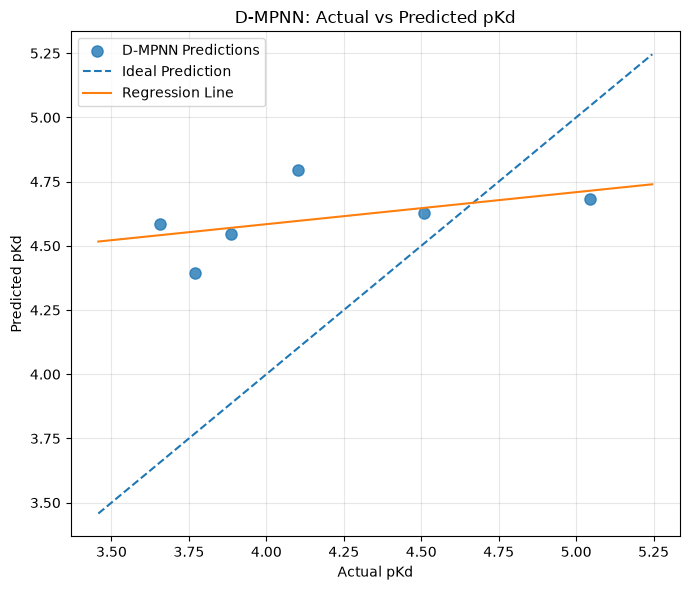

Figure saved: /data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_RandomSplit_Seed42/DMPNN_RandomSplit_Actual_vs_Predicted.png


In [14]:
import matplotlib.pyplot as plt
import numpy as np
import os

y_true = evaluation_df["Actual_pKd"]
y_pred = evaluation_df["Predicted_pKd"]

slope, intercept = np.polyfit(y_true, y_pred, 1)

plot_min = min(y_true.min(), y_pred.min()) - 0.2
plot_max = max(y_true.max(), y_pred.max()) + 0.2

plt.figure(figsize=(7, 6))

plt.scatter(
    y_true,
    y_pred,
    s=65,
    alpha=0.8,
    label="D-MPNN Predictions"
)

plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    linestyle="--",
    label="Ideal Prediction"
)

x_line = np.linspace(plot_min, plot_max, 100)

plt.plot(
    x_line,
    slope * x_line + intercept,
    label="Regression Line"
)

plt.xlabel("Actual pKd")
plt.ylabel("Predicted pKd")
plt.title("D-MPNN: Actual vs Predicted pKd")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

figure_path = os.path.join(
    output_dir,
    "DMPNN_RandomSplit_Actual_vs_Predicted.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", figure_path)

In [15]:
import os
import json
import shutil
import pandas as pd

model_dir = os.path.join(output_dir, "model")

baseline_backup_dir = os.path.join(
    output_dir,
    "baseline_backup"
)

os.makedirs(baseline_backup_dir, exist_ok=True)

# Back up the original split configuration
split_source = os.path.join(model_dir, "splits.json")
split_backup = os.path.join(baseline_backup_dir, "splits.json")

shutil.copy2(split_source, split_backup)

# Back up the original model configuration
config_source = os.path.join(model_dir, "config.toml")
config_backup = os.path.join(baseline_backup_dir, "config.toml")

shutil.copy2(config_source, config_backup)

# Save baseline evaluation metrics
baseline_metrics = {
    "experiment": "DMPNN_RandomSplit_Baseline",
    "seed": 42,
    "epochs": 100,
    "batch_size": 16,
    "message_hidden_dim": 300,
    "depth": 3,
    "dropout": 0.1,
    "test_size": 6,
    "RMSE": 0.6204,
    "MAE": 0.5639,
    "R2": -0.6624
}

metrics_path = os.path.join(
    baseline_backup_dir,
    "baseline_metrics.json"
)

with open(metrics_path, "w") as f:
    json.dump(baseline_metrics, f, indent=4)

print("Baseline backup completed.")
print("Backup directory:", baseline_backup_dir)

Baseline backup completed.
Backup directory: /data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_RandomSplit_Seed42/baseline_backup


In [16]:
with open(split_backup, "r") as f:
    split_data = json.load(f)

print("Split configuration:")
print(json.dumps(split_data, indent=2))

Split configuration:
[
  {
    "train": [
      32,
      38,
      33,
      11,
      2,
      31,
      41,
      29,
      26,
      4,
      10,
      27,
      52,
      30,
      37,
      22,
      7,
      14,
      34,
      48,
      18,
      50,
      35,
      15,
      5,
      28,
      16,
      45,
      20,
      46,
      8,
      13,
      25,
      17,
      51,
      42,
      1,
      12,
      40,
      24,
      6,
      23
    ],
    "val": [
      36,
      21,
      19,
      9,
      39
    ],
    "test": [
      49,
      3,
      0,
      47,
      44,
      43
    ]
  }
]


In [17]:
######################
# OPT_01_Dropout_0.2 #
######################

import subprocess
import sys
import os

experiment_name = "OPT_01_Dropout_02"

experiment_dir = os.path.join(
    output_dir,
    experiment_name
)

os.makedirs(experiment_dir, exist_ok=True)

cli_code = """
from importlib.metadata import entry_points
ep = next(iter(entry_points(group="console_scripts", name="chemprop")))
ep.load()()
"""

cmd = [
    sys.executable,
    "-c", cli_code,
    "train",
    "--data-path", training_data_path,
    "--output-dir", experiment_dir,
    "--task-type", "regression",
    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",
    "--splits-file", split_backup,
    "--pytorch-seed", "42",
    "--epochs", "100",
    "--batch-size", "16",
    "--message-hidden-dim", "300",
    "--depth", "3",
    "--dropout", "0.2",
    "--accelerator", "gpu",
    "--devices", "1",
    "--metrics", "rmse", "mae", "r2"
]

print("Starting experiment:", experiment_name)

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("\nTraining output:")
print(result.stdout[-12000:])

if result.stderr:
    print("\nError output:")
    print(result.stderr[-5000:])

Starting experiment: OPT_01_Dropout_02
Return code: 0

Training output:
                  0.369             
Epoch 97/99 ━━━━━━━━━━━━━━━━━━ 0/3 0:00:00 • 0:00:00 0.00it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.347 val_loss:   
                                                              1.865             
                                                              train_loss_epoch: 
                                                              0.369             
Epoch 97/99 ━━━━━━╺━━━━━━━━━━━ 1/3 0:00:00 • -:--:-- 0.00it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.400 val_loss:   
                                                              1.865             
                                                              train_loss_epoch: 


In [18]:
##################
# OPT_02_Depth_2 #
##################

import subprocess
import sys
import os

experiment_name = "OPT_02_Depth_02"

experiment_dir = os.path.join(
    output_dir,
    experiment_name
)

os.makedirs(experiment_dir, exist_ok=True)

cli_code = """
from importlib.metadata import entry_points
ep = next(iter(entry_points(group="console_scripts", name="chemprop")))
ep.load()()
"""

cmd = [
    sys.executable,
    "-c", cli_code,
    "train",
    "--data-path", training_data_path,
    "--output-dir", experiment_dir,
    "--task-type", "regression",
    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",
    "--splits-file", split_backup,
    "--pytorch-seed", "42",
    "--epochs", "100",
    "--batch-size", "16",
    "--message-hidden-dim", "300",
    "--depth", "2",
    "--dropout", "0.2",
    "--accelerator", "gpu",
    "--devices", "1",
    "--metrics", "rmse", "mae", "r2"
]

print("Starting experiment:", experiment_name)

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-12000:])

if result.stderr:
    print(result.stderr[-5000:])

Starting experiment: OPT_02_Depth_02
Return code: 0
╺━━━━━━━━━━━ 1/3 0:00:00 • -:--:-- 0.00it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.487 val_loss:   
                                                              1.861             
                                                              train_loss_epoch: 
                                                              0.432             
Epoch 97/99 ━━━━━━━━━━━╺━━━━━ 2/3 0:00:00 • 0:00:01 93.81it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.323 val_loss:   
                                                              1.861             
                                                              train_loss_epoch: 
                                                              0.432        

In [19]:
##############################
# OPT_03_Dropout_0.0_Depth_3 #
##############################

import subprocess
import sys
import os

experiment_name = "OPT_03_Dropout_00"

experiment_dir = os.path.join(
    output_dir,
    experiment_name
)

os.makedirs(experiment_dir, exist_ok=True)

cli_code = """
from importlib.metadata import entry_points
ep = next(iter(entry_points(group="console_scripts", name="chemprop")))
ep.load()()
"""

cmd = [
    sys.executable,
    "-c", cli_code,
    "train",
    "--data-path", training_data_path,
    "--output-dir", experiment_dir,
    "--task-type", "regression",
    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",
    "--splits-file", split_backup,
    "--pytorch-seed", "42",
    "--epochs", "100",
    "--batch-size", "16",
    "--message-hidden-dim", "300",
    "--depth", "3",
    "--dropout", "0.0",
    "--accelerator", "gpu",
    "--devices", "1",
    "--metrics", "rmse", "mae", "r2"
]

print("Starting experiment:", experiment_name)

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-12000:])

if result.stderr:
    print(result.stderr[-5000:])

Starting experiment: OPT_03_Dropout_00
Return code: 0
KEpoch 97/99 ━━━━━━━━━━━━━━━━━ 3/3 0:00:00 • 0:00:00 84.40it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.398 val_loss:   
                                                              1.988             
                                                              train_loss_epoch: 
                                                              0.249             
Epoch 97/99 ━━━━━━━━━━━━━━━━━ 3/3 0:00:00 • 0:00:00 84.40it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.398 val_loss:   
                                                              1.988             
                                                              train_loss_epoch: 
                                                      

In [20]:
########################
# OPT_04_HiddenDim_500 #
########################

import subprocess
import sys
import os

experiment_name = "OPT_04_HiddenDim_500"

experiment_dir = os.path.join(
    output_dir,
    experiment_name
)

os.makedirs(experiment_dir, exist_ok=True)

cli_code = """
from importlib.metadata import entry_points
ep = next(iter(entry_points(group="console_scripts", name="chemprop")))
ep.load()()
"""

cmd = [
    sys.executable,
    "-c", cli_code,
    "train",
    "--data-path", training_data_path,
    "--output-dir", experiment_dir,
    "--task-type", "regression",
    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",
    "--splits-file", split_backup,
    "--pytorch-seed", "42",
    "--epochs", "100",
    "--batch-size", "16",
    "--message-hidden-dim", "500",
    "--depth", "3",
    "--dropout", "0.2",
    "--accelerator", "gpu",
    "--devices", "1",
    "--metrics", "rmse", "mae", "r2"
]

print("Starting experiment:", experiment_name)

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-12000:])

if result.stderr:
    print(result.stderr[-5000:])

Starting experiment: OPT_04_HiddenDim_500
Return code: 0
KEpoch 97/99 ━━━━━━━━━━━━━━━━━ 3/3 0:00:00 • 0:00:00 78.35it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.463 val_loss:   
                                                              1.794             
                                                              train_loss_epoch: 
                                                              0.270             
Epoch 97/99 ━━━━━━━━━━━━━━━━━ 3/3 0:00:00 • 0:00:00 78.35it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.463 val_loss:   
                                                              1.794             
                                                              train_loss_epoch: 
                                                   

In [45]:

########################################
# Calculate Mean and SD of Optimization Results
########################################

import pandas as pd
from pathlib import Path

BASE_DIR = Path("/data/Zira/Chemprop_Kd_Mann/2_53")

experiment_names = [
    "DMPNN_RandomSplit_Seed42",
    "OPT_01_Dropout_02",
    "OPT_02_Depth_02",
    "OPT_03_Dropout_00",
    "OPT_04_HiddenDim_500"
]

for experiment in experiment_names:
    print("\nExperiment:", experiment)
    print("Directory:", BASE_DIR / experiment)



Experiment: DMPNN_RandomSplit_Seed42
Directory: /data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_RandomSplit_Seed42

Experiment: OPT_01_Dropout_02
Directory: /data/Zira/Chemprop_Kd_Mann/2_53/OPT_01_Dropout_02

Experiment: OPT_02_Depth_02
Directory: /data/Zira/Chemprop_Kd_Mann/2_53/OPT_02_Depth_02

Experiment: OPT_03_Dropout_00
Directory: /data/Zira/Chemprop_Kd_Mann/2_53/OPT_03_Dropout_00

Experiment: OPT_04_HiddenDim_500
Directory: /data/Zira/Chemprop_Kd_Mann/2_53/OPT_04_HiddenDim_500


In [46]:

########################################
# Calculate Mean and SD of Baseline and Optimization Results
########################################

import pandas as pd

results = {
    "Experiment": [
        "Baseline",
        "OPT-01",
        "OPT-02",
        "OPT-03",
        "OPT-04"
    ],
    "RMSE": [
        0.6204399,
        0.5738801,
        0.6376339,
        0.5881865,
        0.6737604
    ],
    "MAE": [
        0.5639264,
        0.5106652,
        0.5694531,
        0.5341395,
        0.6074259
    ],
    "R2": [
        -0.6624219,
        -0.4222769,
        -0.7558384,
        -0.4940732,
        -0.9604363
    ]
}

results_df = pd.DataFrame(results)

summary = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R2"],
    "Mean": [
        results_df["RMSE"].mean(),
        results_df["MAE"].mean(),
        results_df["R2"].mean()
    ],
    "SD": [
        results_df["RMSE"].std(ddof=1),
        results_df["MAE"].std(ddof=1),
        results_df["R2"].std(ddof=1)
    ]
})

display(results_df)
display(summary)

# Save results
summary.to_csv(
    BASE_DIR / "optimization_mean_sd.csv",
    index=False
)


,Experiment,RMSE,MAE,R2
0,Baseline,0.620440,0.563926,-0.662422
1,OPT-01,0.573880,0.510665,-0.422277
2,OPT-02,0.637634,0.569453,-0.755838
3,OPT-03,0.588186,0.534139,-0.494073
4,OPT-04,0.673760,0.607426,-0.960436


,Metric,Mean,SD
0,RMSE,0.618780,0.039790
1,MAE,0.557122,0.036794
2,R2,-0.659009,0.214180


In [21]:
################################
# Checking Training Log OPT_01 #
################################

import os
import pandas as pd

opt01_dir = os.path.join(
    output_dir,
    "OPT_01_Dropout_02",
    "model_0"
)

metrics_path = os.path.join(
    opt01_dir,
    "trainer_logs",
    "version_0",
    "metrics.csv"
)

metrics_df = pd.read_csv(metrics_path)

print("Metrics shape:", metrics_df.shape)
print("Available columns:")
print(metrics_df.columns.tolist())

display(metrics_df.head())
display(metrics_df.tail())

Metrics shape: (206, 8)
Available columns:
['epoch', 'step', 'train_loss_epoch', 'train_loss_step', 'val/mae', 'val/r2', 'val/rmse', 'val_loss']


,epoch,step,train_loss_epoch,train_loss_step,val/mae,val/r2,val/rmse,val_loss
0,0,2,NaN,NaN,1.104645,-0.031162,1.246252,1.553144
1,0,2,1.011770,NaN,NaN,NaN,NaN,NaN
2,1,5,NaN,NaN,1.111147,-0.041858,1.252699,1.569255
3,1,5,0.999303,NaN,NaN,NaN,NaN,NaN
4,2,8,NaN,NaN,1.111154,-0.041684,1.252594,1.568992


,epoch,step,train_loss_epoch,train_loss_step,val/mae,val/r2,val/rmse,val_loss
201,98,296,NaN,NaN,1.145709,-0.214207,1.352349,1.828848
202,98,296,0.344041,NaN,NaN,NaN,NaN,NaN
203,99,299,NaN,0.18638,NaN,NaN,NaN,NaN
204,99,299,NaN,NaN,1.205519,-0.313191,1.406392,1.977939
205,99,299,0.347640,NaN,NaN,NaN,NaN,NaN


In [22]:
############################
# Checking Validation Loss #
############################

validation_columns = [
    col for col in metrics_df.columns
    if "val" in col.lower()
]

print("Validation columns:", validation_columns)

display(
    metrics_df[validation_columns].dropna(how="all").tail(10)
)

Validation columns: ['val/mae', 'val/r2', 'val/rmse', 'val_loss']


,val/mae,val/r2,val/rmse,val_loss
185,1.239566,-0.380204,1.441830,2.078875
187,1.142315,-0.209935,1.349968,1.822414
189,1.142946,-0.213037,1.351697,1.827085
191,1.132645,-0.175826,1.330803,1.771038
193,1.165205,-0.248521,1.371325,1.880532
195,1.216032,-0.334668,1.417846,2.010287
197,1.159564,-0.238421,1.365767,1.865319
199,1.128037,-0.167004,1.325802,1.757751
201,1.145709,-0.214207,1.352349,1.828848
204,1.205519,-0.313191,1.406392,1.977939


In [24]:
######################################
# Searching the best epoch of OPT_01 #
######################################

validation_df = metrics_df.dropna(
    subset=["val_loss"]
).copy()

best_row = validation_df.loc[
    validation_df["val_loss"].idxmin()
]

print("Best epoch:", int(best_row["epoch"]))
print("Best validation loss:", best_row["val_loss"])
print("Best validation RMSE:", best_row["val/rmse"])
print("Best validation MAE:", best_row["val/mae"])
print("Best validation R2:", best_row["val/r2"])

Best epoch: 61
Best validation loss: 1.463883399963379
Best validation RMSE: 1.20991051197052
Best validation MAE: 1.0782794952392578
Best validation R2: 0.028100013732910156


In [25]:
#################################
# Trying Eraly Stopping Methode #
#################################

In [26]:
import inspect
from chemprop import cli

help_text = cli.train.__doc__

print(help_text)

AttributeError: module 'chemprop.cli' has no attribute 'train'

In [27]:
import subprocess
import sys

cli_code = """
from importlib.metadata import entry_points
ep = next(iter(entry_points(group="console_scripts", name="chemprop")))
ep.load()()
"""

result = subprocess.run(
    [sys.executable, "-c", cli_code, "train", "--help"],
    capture_output=True,
    text=True
)

for line in result.stdout.splitlines():
    if "patience" in line.lower() or "early" in line.lower():
        print(line)

                [--patience PATIENCE] [--min-delta MIN_DELTA]
                        the 0-th one will be used for early stopping and
                        The metric to track for early stopping, checkpointing,
                        linearly from ``init_lr`` to ``max_lr`` (afterwards,
  --patience PATIENCE   Number of epochs to wait for improvement before early


In [28]:
############################
# OP5_05_Early stopping_15 #
############################

import subprocess
import sys
import os

experiment_name = "OPT_05_EarlyStopping"

experiment_dir = os.path.join(
    output_dir,
    experiment_name
)

os.makedirs(experiment_dir, exist_ok=True)

cli_code = """
from importlib.metadata import entry_points
ep = next(iter(entry_points(group="console_scripts", name="chemprop")))
ep.load()()
"""

cmd = [
    sys.executable,
    "-c", cli_code,
    "train",
    "--data-path", training_data_path,
    "--output-dir", experiment_dir,
    "--task-type", "regression",
    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",
    "--splits-file", split_backup,
    "--pytorch-seed", "42",
    "--epochs", "100",
    "--patience", "15",
    "--batch-size", "16",
    "--message-hidden-dim", "300",
    "--depth", "3",
    "--dropout", "0.2",
    "--accelerator", "gpu",
    "--devices", "1",
    "--metrics", "rmse", "mae", "r2"
]

print("Starting experiment:", experiment_name)

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-12000:])

if result.stderr:
    print(result.stderr[-5000:])

Starting experiment: OPT_05_EarlyStopping
Return code: 0
000      
                                                              train_loss_step:  
                                                              0.771 val_loss:   
                                                              1.725             
                                                              train_loss_epoch: 
                                                              0.523             
Epoch 51/99 ━━━━━━━━━━━━━━━━━ 3/3 0:00:00 • 0:00:00 77.16it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.160 val_loss:   
                                                              1.725             
                                                              train_loss_epoch: 
                                                              0.523             
Epoch 51/99 ━━━━━━━━━━━━━━━━━ 3/3 0:00:00 

In [29]:
import os
import pandas as pd

opt05_metrics_path = os.path.join(
    output_dir,
    "OPT_05_EarlyStopping",
    "model_0",
    "trainer_logs",
    "version_0",
    "metrics.csv"
)

opt05_metrics = pd.read_csv(opt05_metrics_path)

validation_df = opt05_metrics.dropna(
    subset=["val_loss"]
).copy()

best_row = validation_df.loc[
    validation_df["val_loss"].idxmin()
]

print("Best epoch:", int(best_row["epoch"]))
print("Best validation loss:", best_row["val_loss"])
print("Best validation RMSE:", best_row["val/rmse"])
print("Best validation MAE:", best_row["val/mae"])
print("Best validation R2:", best_row["val/r2"])

print("\nLast recorded epoch:", int(validation_df["epoch"].max()))

Best epoch: 38
Best validation loss: 1.4770700931549072
Best validation RMSE: 1.2153477668762207
Best validation MAE: 1.0986223220825195
Best validation R2: 0.01934516429901123

Last recorded epoch: 53


In [31]:
######################################
# Trying optimization using seed 123 #
######################################

In [32]:
########################################
# Creating Random Split for Seed 123
########################################

import os
import json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

seed = 123

experiment_name = "DMPNN_OPT05_Seed123"

experiment_dir = os.path.join(
    base_dir,
    experiment_name
)

os.makedirs(experiment_dir, exist_ok=True)

# Load the original dataset
df = pd.read_csv(data_path)

# Generate random train, validation, and test indices
indices = np.arange(len(df))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=seed
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5454545,
    random_state=seed
)

# Create Chemprop split configuration
split_data = [{
    "train": train_idx.tolist(),
    "val": val_idx.tolist(),
    "test": test_idx.tolist()
}]

split_path = os.path.join(
    experiment_dir,
    "splits_seed123.json"
)

with open(split_path, "w") as f:
    json.dump(split_data, f, indent=4)

print("Random split created successfully.")
print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Testing samples:", len(test_idx))
print("Total samples:", len(indices))
print("Split file:", split_path)

Random split created successfully.
Training samples: 42
Validation samples: 5
Testing samples: 6
Total samples: 53
Split file: /data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_OPT05_Seed123/splits_seed123.json


In [33]:
########################################
# Checking Seed 123 Data Distribution
########################################

train_data = df.iloc[train_idx]
val_data = df.iloc[val_idx]
test_data = df.iloc[test_idx]

distribution = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "N": [
        len(train_data),
        len(val_data),
        len(test_data)
    ],
    "Mean_pKd": [
        train_data["pKd"].mean(),
        val_data["pKd"].mean(),
        test_data["pKd"].mean()
    ],
    "Std_pKd": [
        train_data["pKd"].std(),
        val_data["pKd"].std(),
        test_data["pKd"].std()
    ],
    "Min_pKd": [
        train_data["pKd"].min(),
        val_data["pKd"].min(),
        test_data["pKd"].min()
    ],
    "Max_pKd": [
        train_data["pKd"].max(),
        val_data["pKd"].max(),
        test_data["pKd"].max()
    ]
})

display(distribution)

,Dataset,N,Mean_pKd,Std_pKd,Min_pKd,Max_pKd
0,Training,42,4.446920,0.416639,3.568636,5.552842
1,Validation,5,4.250736,0.493250,3.886057,5.045757
2,Testing,6,4.144310,0.715025,3.657577,5.468521


In [34]:
########################################
# Training D-MPNN with Seed 123
########################################

import subprocess
import sys
import os

experiment_name = "DMPNN_OPT05_Seed123"

experiment_dir = os.path.join(
    base_dir,
    experiment_name,
    "model"
)

os.makedirs(experiment_dir, exist_ok=True)

cli_code = """
from importlib.metadata import entry_points
ep = next(iter(entry_points(group="console_scripts", name="chemprop")))
ep.load()()
"""

cmd = [
    sys.executable,
    "-c", cli_code,
    "train",
    "--data-path", training_data_path,
    "--output-dir", experiment_dir,
    "--task-type", "regression",
    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",
    "--splits-file", split_path,
    "--pytorch-seed", "123",
    "--epochs", "100",
    "--patience", "15",
    "--batch-size", "16",
    "--message-hidden-dim", "300",
    "--depth", "3",
    "--dropout", "0.2",
    "--accelerator", "gpu",
    "--devices", "1",
    "--metrics", "rmse", "mae", "r2"
]

print("Starting experiment:", experiment_name)

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-12000:])

if result.stderr:
    print("\nError output:")
    print(result.stderr[-5000:])

Starting experiment: DMPNN_OPT05_Seed123
Return code: 0
                                    0.299             
Epoch 97/99 ━━━━━━━━━━━╺━━━━━ 2/3 0:00:00 • 0:00:01 80.55it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.226 val_loss:   
                                                              0.548             
                                                              train_loss_epoch: 
                                                              0.299             
Epoch 97/99 ━━━━━━━━━━━━━━━━━ 3/3 0:00:00 • 0:00:00 81.78it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.173 val_loss:   
                                                              0.548             
                                                              train_loss_epoch:

In [35]:
######################################
# Trying optimization using seed 202 #
######################################

In [36]:
########################################
# Creating Random Split for Seed 202
########################################

import os
import json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

seed = 202

experiment_name = "DMPNN_OPT05_Seed202"

experiment_dir = os.path.join(
    base_dir,
    experiment_name
)

os.makedirs(experiment_dir, exist_ok=True)

df = pd.read_csv(data_path)

indices = np.arange(len(df))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=seed
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5454545,
    random_state=seed
)

split_data = [{
    "train": train_idx.tolist(),
    "val": val_idx.tolist(),
    "test": test_idx.tolist()
}]

split_path_202 = os.path.join(
    experiment_dir,
    "splits_seed202.json"
)

with open(split_path_202, "w") as f:
    json.dump(split_data, f, indent=4)

print("Random split created successfully.")
print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Testing samples:", len(test_idx))
print("Split file:", split_path_202)

Random split created successfully.
Training samples: 42
Validation samples: 5
Testing samples: 6
Split file: /data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_OPT05_Seed202/splits_seed202.json


In [37]:
########################################
# Training D-MPNN with Seed 202
########################################

import subprocess
import sys
import os

experiment_name = "DMPNN_OPT05_Seed202"

experiment_dir = os.path.join(
    base_dir,
    experiment_name,
    "model"
)

os.makedirs(experiment_dir, exist_ok=True)

cli_code = """
from importlib.metadata import entry_points
ep = next(iter(entry_points(group="console_scripts", name="chemprop")))
ep.load()()
"""

cmd = [
    sys.executable,
    "-c", cli_code,
    "train",
    "--data-path", training_data_path,
    "--output-dir", experiment_dir,
    "--task-type", "regression",
    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",
    "--splits-file", split_path_202,
    "--pytorch-seed", "202",
    "--epochs", "100",
    "--patience", "15",
    "--batch-size", "16",
    "--message-hidden-dim", "300",
    "--depth", "3",
    "--dropout", "0.2",
    "--accelerator", "gpu",
    "--devices", "1",
    "--metrics", "rmse", "mae", "r2"
]

print("Starting experiment:", experiment_name)

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-12000:])

if result.stderr:
    print("\nError output:")
    print(result.stderr[-5000:])

Starting experiment: DMPNN_OPT05_Seed202
Return code: 0
99 ━━━━━━━━━━━╺━━━━━ 2/3 0:00:00 • 0:00:01 79.24it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              1.173 val_loss:   
                                                              1.201             
                                                              train_loss_epoch: 
                                                              1.002             
Epoch 13/99 ━━━━━━━━━━━━━━━━━ 3/3 0:00:00 • 0:00:00 79.23it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.725 val_loss:   
                                                              1.201             
                                                              train_loss_epoch: 
                                                              

In [38]:
######################################
# Trying optimization using seed 303 #
######################################

In [39]:
########################################
# Creating Random Split for Seed 303
########################################

import os
import json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

seed = 303

experiment_name = "DMPNN_OPT05_Seed303"

experiment_dir = os.path.join(
    base_dir,
    experiment_name
)

os.makedirs(experiment_dir, exist_ok=True)

df = pd.read_csv(data_path)

indices = np.arange(len(df))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=seed
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5454545,
    random_state=seed
)

split_data = [{
    "train": train_idx.tolist(),
    "val": val_idx.tolist(),
    "test": test_idx.tolist()
}]

split_path_303 = os.path.join(
    experiment_dir,
    "splits_seed303.json"
)

with open(split_path_303, "w") as f:
    json.dump(split_data, f, indent=4)

print("Random split created successfully.")
print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Testing samples:", len(test_idx))
print("Split file:", split_path_303)

Random split created successfully.
Training samples: 42
Validation samples: 5
Testing samples: 6
Split file: /data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_OPT05_Seed303/splits_seed303.json


In [40]:
########################################
# Training D-MPNN with Seed 303
########################################

import subprocess
import sys
import os

experiment_name = "DMPNN_OPT05_Seed303"

experiment_dir = os.path.join(
    base_dir,
    experiment_name,
    "model"
)

os.makedirs(experiment_dir, exist_ok=True)

cli_code = """
from importlib.metadata import entry_points
ep = next(iter(entry_points(group="console_scripts", name="chemprop")))
ep.load()()
"""

cmd = [
    sys.executable,
    "-c", cli_code,
    "train",
    "--data-path", training_data_path,
    "--output-dir", experiment_dir,
    "--task-type", "regression",
    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",
    "--splits-file", split_path_303,
    "--pytorch-seed", "303",
    "--epochs", "100",
    "--patience", "15",
    "--batch-size", "16",
    "--message-hidden-dim", "300",
    "--depth", "3",
    "--dropout", "0.2",
    "--accelerator", "gpu",
    "--devices", "1",
    "--metrics", "rmse", "mae", "r2"
]

print("Starting experiment:", experiment_name)

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-12000:])

if result.stderr:
    print("\nError output:")
    print(result.stderr[-5000:])

Starting experiment: DMPNN_OPT05_Seed303
Return code: 0
000      
                                                              train_loss_step:  
                                                              0.248 val_loss:   
                                                              1.379             
                                                              train_loss_epoch: 
                                                              0.290             
Epoch 97/99 ━━━━━━━━━━━━━━━━━ 3/3 0:00:00 • 0:00:00 76.89it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.248 val_loss:   
                                                              1.379             
                                                              train_loss_epoch: 
                                                              0.290             
Epoch 97/99 ━━━━━━━━━━━━━━━━━ 3/3 0:00:00 •

In [41]:
######################################
# Trying optimization using seed 404 #
######################################

In [42]:
########################################
# Creating Random Split for Seed 404
########################################

import os
import json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

seed = 404

experiment_name = "DMPNN_OPT05_Seed404"

experiment_dir = os.path.join(
    base_dir,
    experiment_name
)

os.makedirs(experiment_dir, exist_ok=True)

df = pd.read_csv(data_path)

indices = np.arange(len(df))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=seed
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5454545,
    random_state=seed
)

split_data = [{
    "train": train_idx.tolist(),
    "val": val_idx.tolist(),
    "test": test_idx.tolist()
}]

split_path_404 = os.path.join(
    experiment_dir,
    "splits_seed404.json"
)

with open(split_path_404, "w") as f:
    json.dump(split_data, f, indent=4)

print("Random split created successfully.")
print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Testing samples:", len(test_idx))
print("Split file:", split_path_404)

Random split created successfully.
Training samples: 42
Validation samples: 5
Testing samples: 6
Split file: /data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_OPT05_Seed404/splits_seed404.json


In [43]:
########################################
# Training D-MPNN with Seed 404
########################################

import subprocess
import sys
import os

experiment_name = "DMPNN_OPT05_Seed404"

experiment_dir = os.path.join(
    base_dir,
    experiment_name,
    "model"
)

os.makedirs(experiment_dir, exist_ok=True)

cli_code = """
from importlib.metadata import entry_points
ep = next(iter(entry_points(group="console_scripts", name="chemprop")))
ep.load()()
"""

cmd = [
    sys.executable,
    "-c", cli_code,
    "train",
    "--data-path", training_data_path,
    "--output-dir", experiment_dir,
    "--task-type", "regression",
    "--smiles-columns", "Smiles",
    "--target-columns", "pKd",
    "--splits-file", split_path_404,
    "--pytorch-seed", "404",
    "--epochs", "100",
    "--patience", "15",
    "--batch-size", "16",
    "--message-hidden-dim", "300",
    "--depth", "3",
    "--dropout", "0.2",
    "--accelerator", "gpu",
    "--devices", "1",
    "--metrics", "rmse", "mae", "r2"
]

print("Starting experiment:", experiment_name)

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-12000:])

if result.stderr:
    print("\nError output:")
    print(result.stderr[-5000:])

Starting experiment: DMPNN_OPT05_Seed404
Return code: 0
99 ━━━━━━━━━━━╺━━━━━ 2/3 0:00:00 • 0:00:01 81.75it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.449 val_loss:   
                                                              0.826             
                                                              train_loss_epoch: 
                                                              0.520             
Epoch 45/99 ━━━━━━━━━━━━━━━━━ 3/3 0:00:00 • 0:00:00 80.94it/s v_num: 0.000      
                                                              train_loss_step:  
                                                              0.714 val_loss:   
                                                              0.826             
                                                              train_loss_epoch: 
                                                              

In [44]:
########################################
# Summarizing D-MPNN Results Across Seeds
########################################

import pandas as pd
import numpy as np
import os

results = pd.DataFrame({
    "Seed": [42, 123, 202, 303, 404],
    "RMSE": [0.5697002, 0.5673788, 0.6154109, 0.3600544, 0.4464765],
    "MAE": [0.5102831, 0.4807381, 0.4923337, 0.3106600, 0.4116338],
    "R2": [-0.4016335, 0.2444134, -0.0435019, -0.2844422, 0.1524963]
})

summary = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R2"],
    "Mean": [
        results["RMSE"].mean(),
        results["MAE"].mean(),
        results["R2"].mean()
    ],
    "SD": [
        results["RMSE"].std(ddof=1),
        results["MAE"].std(ddof=1),
        results["R2"].std(ddof=1)
    ]
})

results_path = os.path.join(
    base_dir,
    "DMPNN_OPT05_Five_Seeds_Results.csv"
)

summary_path = os.path.join(
    base_dir,
    "DMPNN_OPT05_Five_Seeds_Summary.csv"
)

results.to_csv(results_path, index=False)
summary.to_csv(summary_path, index=False)

print("Individual results:")
display(results)

print("Mean and standard deviation:")
display(summary)

print("Results saved:", results_path)
print("Summary saved:", summary_path)

Individual results:


,Seed,RMSE,MAE,R2
0,42,0.569700,0.510283,-0.401633
1,123,0.567379,0.480738,0.244413
2,202,0.615411,0.492334,-0.043502
3,303,0.360054,0.310660,-0.284442
4,404,0.446476,0.411634,0.152496


Mean and standard deviation:


,Metric,Mean,SD
0,RMSE,0.511804,0.105440
1,MAE,0.441130,0.081953
2,R2,-0.066534,0.276120


Results saved: /data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_OPT05_Five_Seeds_Results.csv
Summary saved: /data/Zira/Chemprop_Kd_Mann/2_53/DMPNN_OPT05_Five_Seeds_Summary.csv
